## Import library

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

pd.set_option('display.max_columns', None)

## Collect data raw

In [2]:
from pathlib import Path

BASE_PATH = Path.cwd().parent
DATA_PATH = BASE_PATH / "researchment" / "database" / "indonesia_fintech_p2p_paylater_enriched_2026.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)
df.head()

,borrower_id,age,gender,province,education_level,employment_status,monthly_income_idr,regional_minimum_wage_umr_idr,num_active_lending_apps,total_loan_outstanding_idr,credit_limit_granted_idr,loan_tenor_months,daily_interest_rate_pct,primary_loan_purpose,debt_to_income_ratio,income_to_umr_ratio,credit_limit_utilization_ratio,monthly_installment_estimate_idr,debt_service_ratio,disposable_income_after_debt_idr,days_past_due,financial_distress_index,twp90_default_status,primary_default_root_cause,cot_financial_psychology_rationale,confidence_score
0,ID_DEB_00264B68D1,24,Female,Bali,High School / SMK,Micro-Entrepreneur / UMKM,6420000,2950000,2,8380000,12280000,1,0.35,Daily Living & Emergency Buffer,1.31,2.18,0.6824,9259900.0,1.4424,-2839900.0,67,3.97,Doubtful-DPD61-90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_00264B68D1' (Female, usia 24 t...",0.961
1,ID_DEB_0DE3583B12,28,Female,Bali,Bachelor (S1),Formal Private Employee,8630000,2950000,1,20110000,29060000,6,0.30,Daily Living & Emergency Buffer,2.33,2.93,0.6920,5161567.0,0.5981,3468433.0,11,4.87,Special-Mention-DPD1-30,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0DE3583B12' (Female, usia 28 t...",0.975
2,ID_DEB_0F661FADC0,20,Female,Bali,High School / SMK,Civil Servant / BUMN,5720000,2950000,4,14960000,23900000,1,0.32,Daily Living & Emergency Buffer,2.62,1.94,0.6259,16396160.0,2.8665,-10676160.0,180,6.07,Default-Macet-TWP90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0F661FADC0' (Female, usia 20 t...",0.990
3,ID_DEB_10C74D3F21,31,Female,Bali,Bachelor (S1),Civil Servant / BUMN,11780000,2950000,3,7620000,26130000,1,0.26,Daily Living & Emergency Buffer,0.65,3.99,0.2916,8214360.0,0.6973,3565640.0,24,2.35,Special-Mention-DPD1-30,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_10C74D3F21' (Female, usia 31 t...",0.977
4,ID_DEB_12CFCAE01F,22,Male,Bali,Bachelor (S1),Formal Private Employee,6490000,2950000,2,11080000,16420000,9,0.23,Daily Living & Emergency Buffer,1.71,2.20,0.6748,1995631.0,0.3075,4494369.0,0,4.43,Current-Performing,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_12CFCAE01F' (Male, usia 22 tah...",0.980


In [3]:
print(f"Amount of missing values in each column:{len(df.columns[df.isnull().any()])}")

Amount of missing values in each column:0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   borrower_id                         10000 non-null  object 
 1   age                                 10000 non-null  int64  
 2   gender                              10000 non-null  object 
 3   province                            10000 non-null  object 
 4   education_level                     10000 non-null  object 
 5   employment_status                   10000 non-null  object 
 6   monthly_income_idr                  10000 non-null  int64  
 7   regional_minimum_wage_umr_idr       10000 non-null  int64  
 8   num_active_lending_apps             10000 non-null  int64  
 9   total_loan_outstanding_idr          10000 non-null  int64  
 10  credit_limit_granted_idr            10000 non-null  int64  
 11  loan_tenor_months                   10000 

## Data visualizaion analytics

### Label Meaning	Risk Level
* ### Current-Performing	No issue	🟢 Lowest
* ### Special-Mention-DPD1-30	1–30 days late	🟡 Low
* ### Substandard-DPD31-60	31–60 days late	🟠 Medium
* ### Doubtful-DPD61-90	61–90 days late	🔴 High
* ### Default-Macet-TWP90	>90 days late (written off)	⚫ Critical


In [5]:
df

,borrower_id,age,gender,province,education_level,employment_status,monthly_income_idr,regional_minimum_wage_umr_idr,num_active_lending_apps,total_loan_outstanding_idr,credit_limit_granted_idr,loan_tenor_months,daily_interest_rate_pct,primary_loan_purpose,debt_to_income_ratio,income_to_umr_ratio,credit_limit_utilization_ratio,monthly_installment_estimate_idr,debt_service_ratio,disposable_income_after_debt_idr,days_past_due,financial_distress_index,twp90_default_status,primary_default_root_cause,cot_financial_psychology_rationale,confidence_score
0,ID_DEB_00264B68D1,24,Female,Bali,High School / SMK,Micro-Entrepreneur / UMKM,6420000,2950000,2,8380000,12280000,1,0.35,Daily Living & Emergency Buffer,1.31,2.18,0.6824,9259900.0,1.4424,-2839900.0,67,3.97,Doubtful-DPD61-90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_00264B68D1' (Female, usia 24 t...",0.961
1,ID_DEB_0DE3583B12,28,Female,Bali,Bachelor (S1),Formal Private Employee,8630000,2950000,1,20110000,29060000,6,0.30,Daily Living & Emergency Buffer,2.33,2.93,0.6920,5161567.0,0.5981,3468433.0,11,4.87,Special-Mention-DPD1-30,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0DE3583B12' (Female, usia 28 t...",0.975
2,ID_DEB_0F661FADC0,20,Female,Bali,High School / SMK,Civil Servant / BUMN,5720000,2950000,4,14960000,23900000,1,0.32,Daily Living & Emergency Buffer,2.62,1.94,0.6259,16396160.0,2.8665,-10676160.0,180,6.07,Default-Macet-TWP90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0F661FADC0' (Female, usia 20 t...",0.990
3,ID_DEB_10C74D3F21,31,Female,Bali,Bachelor (S1),Civil Servant / BUMN,11780000,2950000,3,7620000,26130000,1,0.26,Daily Living & Emergency Buffer,0.65,3.99,0.2916,8214360.0,0.6973,3565640.0,24,2.35,Special-Mention-DPD1-30,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_10C74D3F21' (Female, usia 31 t...",0.977
4,ID_DEB_12CFCAE01F,22,Male,Bali,Bachelor (S1),Formal Private Employee,6490000,2950000,2,11080000,16420000,9,0.23,Daily Living & Emergency Buffer,1.71,2.20,0.6748,1995631.0,0.3075,4494369.0,0,4.43,Current-Performing,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_12CFCAE01F' (Male, usia 22 tah...",0.980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,ID_DEB_F444AA1239,30,Female,Sumatera Utara,High School / SMK,Formal Private Employee,4530000,2900000,5,7270000,6000000,3,0.37,Online Gambling / Speculative Trading,1.60,1.56,1.2117,3230303.0,0.7131,1299697.0,116,6.32,Default-Macet-TWP90,Speculative-Losses,"Debitur 'ID_DEB_F444AA1239' (Female, usia 30 t...",0.989
9996,ID_DEB_F7A9319108,34,Male,Sumatera Utara,Bachelor (S1),Gig Worker / Ojol,3580000,2900000,7,4510000,4610000,12,0.39,Online Gambling / Speculative Trading,1.26,1.23,0.9783,903503.0,0.2524,2676497.0,54,6.55,Substandard-DPD31-60,Speculative-Losses,"Debitur 'ID_DEB_F7A9319108' (Male, usia 34 tah...",0.952
9997,ID_DEB_FA8D7A7955,32,Male,Sumatera Utara,Bachelor (S1),Digital Freelancer / Creator,9740000,2900000,6,37330000,40510000,1,0.33,Online Gambling / Speculative Trading,3.83,3.36,0.9215,41025670.0,4.2121,-31285670.0,180,8.51,Default-Macet-TWP90,Speculative-Losses,"Debitur 'ID_DEB_FA8D7A7955' (Male, usia 32 tah...",0.990
9998,ID_DEB_FDEDB5CA7C,21,Female,Sumatera Utara,High School / SMK,Gig Worker / Ojol,2670000,2900000,6,4290000,4170000,3,0.27,Online Gambling / Speculative Trading,1.61,0.92,1.0288,1777490.0,0.6657,892510.0,112,6.68,Default-Macet-TWP90,Speculative-Losses,"Debitur 'ID_DEB_FDEDB5CA7C' (Female, usia 21 t...",0.988


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Helper to format IDR amounts
def idr_fmt(x, pos=None):
    if x >= 1000000000:
        return f'Rp {x*1e-9:.1f}B'
    elif x >= 1000000:
        return f'Rp {x*1e-6:.1f}M'
    elif x >= 1000:
        return f'Rp {x*1e-3:.1f}K'
    return f'Rp {x:.0f}'

# ---- Ordinal risk ordering (lowest -> highest risk) ----
RISK_ORDER = [
    'Current-Performing',
    'Special-Mention-DPD1-30',
    'Substandard-DPD31-60',
    'Doubtful-DPD61-90',
    'Default-Macet-TWP90',
]
df['twp90_default_status'] = pd.Categorical(df['twp90_default_status'], categories=RISK_ORDER, ordered=True)
df['risk_score'] = df['twp90_default_status'].cat.codes # Ordinal numeric encoding for correlation analysis

# Short label for tight legends
SHORT = {
    'Current-Performing':'Current',
    'Special-Mention-DPD1-30':'SM(1-30)',
    'Substandard-DPD31-60':'Sub(31-60)',
    'Doubtful-DPD61-90':'Doubt(61-90)',
    'Default-Macet-TWP90':'Default Rate(>90)',
}
df['risk_short'] = df['twp90_default_status'].map(SHORT)

# Risk color palette (green -> black)
RISK_PALETTE = ['#2E8B57','#F4D03F','#F39C12','#E74C3C','#2C3E50']

# "High risk" flag (DPD > 60) - useful for binary KPIs
df['is_high_risk'] = df['risk_score'] >= 3
print(df['twp90_default_status'].value_counts().sort_index())

twp90_default_status
Current-Performing         3508
Special-Mention-DPD1-30    1731
Substandard-DPD31-60       1367
Doubtful-DPD61-90           856
Default-Macet-TWP90        2538
Name: count, dtype: int64


## Ordinal Distribution — Bar with Cumulative Line
### Shows both the class volume AND the cumulative risk curve — a common credit-risk chart (like a "risk migration waterfall").

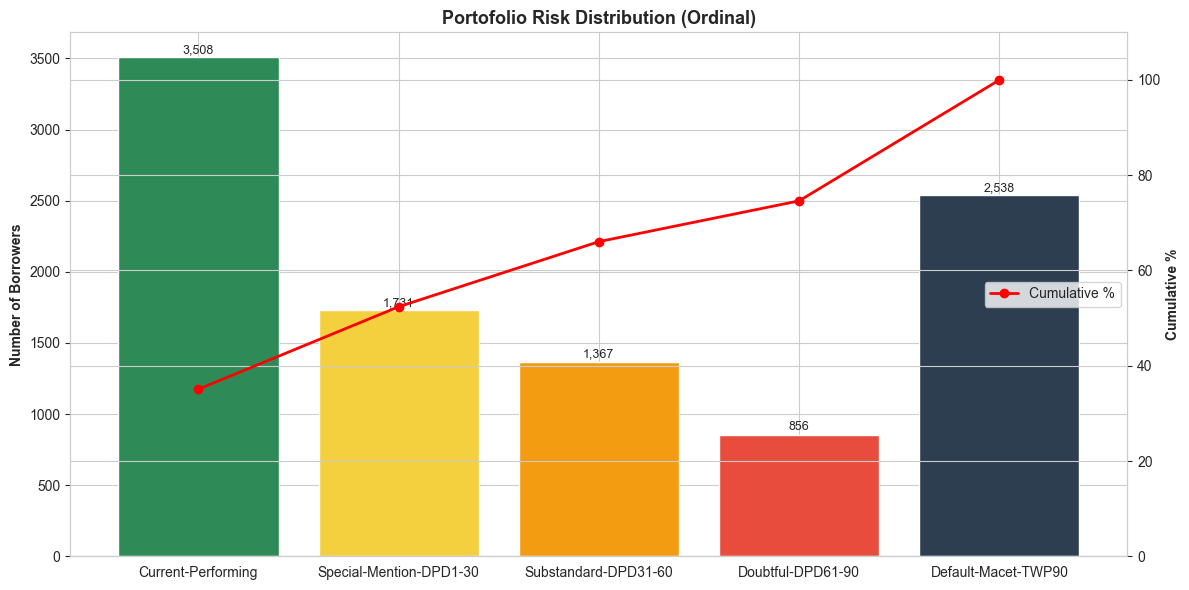

In [7]:
counts= df['twp90_default_status'].value_counts().sort_index()
cum_pct = counts.cumsum() / counts.sum() * 100

fig, ax1 = plt.subplots(figsize=(12, 6))
bars = ax1.bar(counts.index, counts.values, color=RISK_PALETTE)
ax1.set_ylabel('Number of Borrowers', fontweight='bold')
ax1.set_title('Portofolio Risk Distribution (Ordinal)')

for b, v in zip(bars, counts.values):
    ax1.text(b.get_x() + b.get_width()/2, v + 30, f'{v:,}', ha='center', fontsize=9)

ax2 = ax1.twinx()
ax2.plot(counts.index, cum_pct.values, 'o-', color='red', lw=2, label='Cumulative %')
ax2.set_ylabel('Cumulative %', fontweight='bold')
ax2.set_ylim(0, 110)
ax2.legend(loc='center right')

plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## Stacked 100% Bar — Risk Profile by Employment Status
### Shows the full risk composition of each employment segment, not just a single default rate. Reveals where subprime risk concentrates.

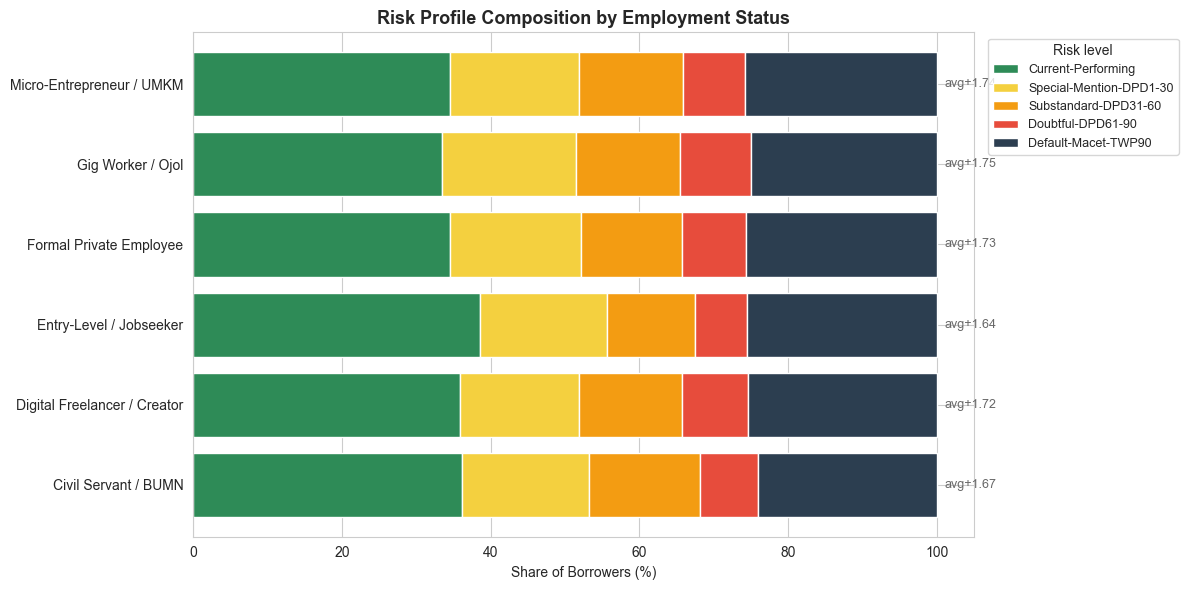

In [8]:
stack = pd.crosstab(df['employment_status'], df['twp90_default_status'], normalize='index') * 100
stack = stack[RISK_ORDER]  # Ensure correct order

ax = stack.plot(kind='barh', stacked=True, figsize=(12, 6), color=RISK_PALETTE, edgecolor='white', width=0.8)
ax.set_title('Risk Profile Composition by Employment Status')
ax.set_xlabel('Share of Borrowers (%)')
ax.set_ylabel('')
ax.legend(title='Risk level', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)

# Annotate overall risk score
for i, emp in enumerate(stack.index):
    score = df.loc[df['employment_status'] == emp, 'risk_score'].mean()
    ax.text(101, i, f'avg+{score:.2f}', va='center', fontsize=9, color='dimgray')

plt.tight_layout()
plt.show()

## Boxplot — DTI Across Risk Levels (With Mean Marker)
### Treats risk as ordinal X-axis to reveal monotonic trends (as DTI rises, does risk level rise?).

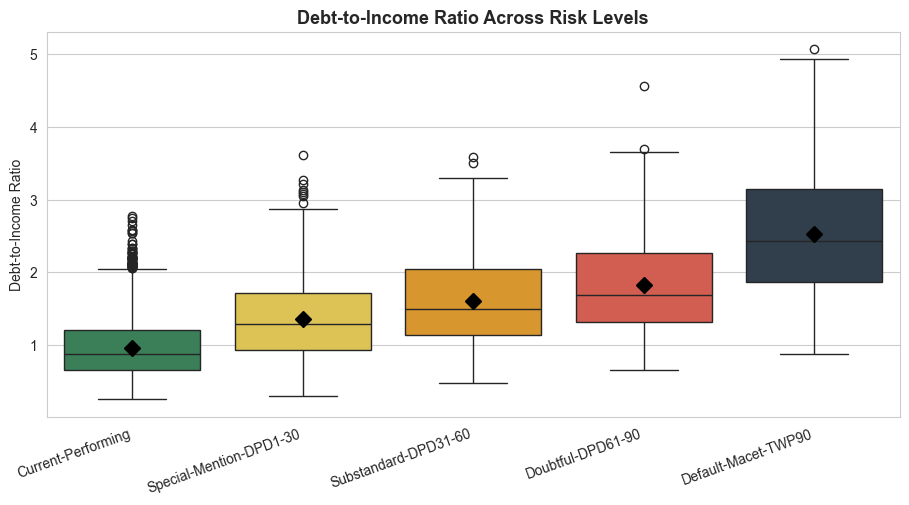

In [9]:
plt.figure(figsize=(11,5))
sns.boxplot(data=df, x='twp90_default_status', y='debt_to_income_ratio',
            palette=RISK_PALETTE, showmeans=True,
            meanprops={'marker':'D','markerfacecolor':'black','markeredgecolor':'black','markersize':8})
plt.title('Debt-to-Income Ratio Across Risk Levels')
plt.xticks(rotation=20, ha='right'); plt.xlabel(''); plt.ylabel('Debt-to-Income Ratio')
plt.show()

## Violin — Utilization Ratio Across Ordinal Risk
### split across 5 risk bands with a mean-line — reveals if the shape of leverage changes as delinquency worsens.

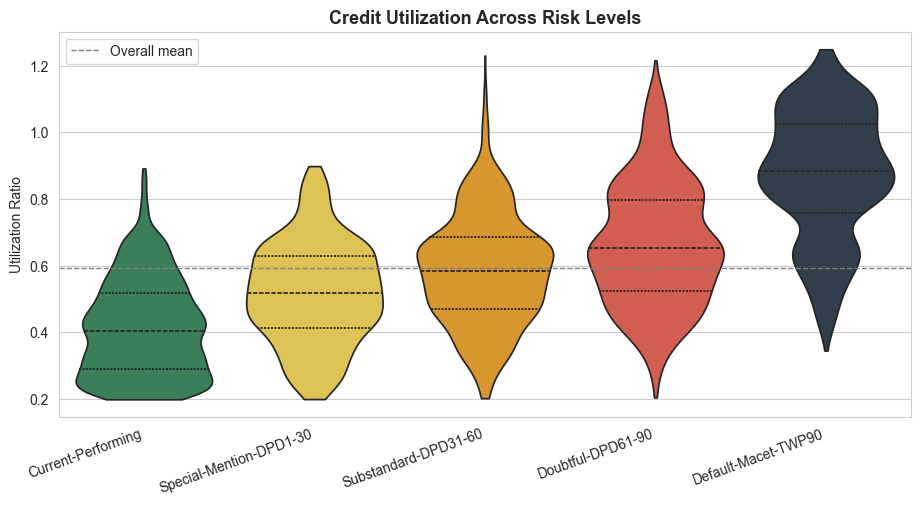

In [10]:
plt.figure(figsize=(11,5))
sns.violinplot(data=df, x='twp90_default_status', y='credit_limit_utilization_ratio',
               palette=RISK_PALETTE, inner='quart', cut=0)
plt.axhline(df['credit_limit_utilization_ratio'].mean(), color='gray', ls='--', lw=1, label='Overall mean')
plt.title('Credit Utilization Across Risk Levels')
plt.xlabel(''); plt.ylabel('Utilization Ratio')
plt.xticks(rotation=20, ha='right')
plt.legend()
plt.show()

## Province Risk Heatmap — Top Provinces × Risk Levels (%)
### Instead of default rate (binary), you now see how each province's portfolio is composed across the 5 bands — a much richer risk zoning view.

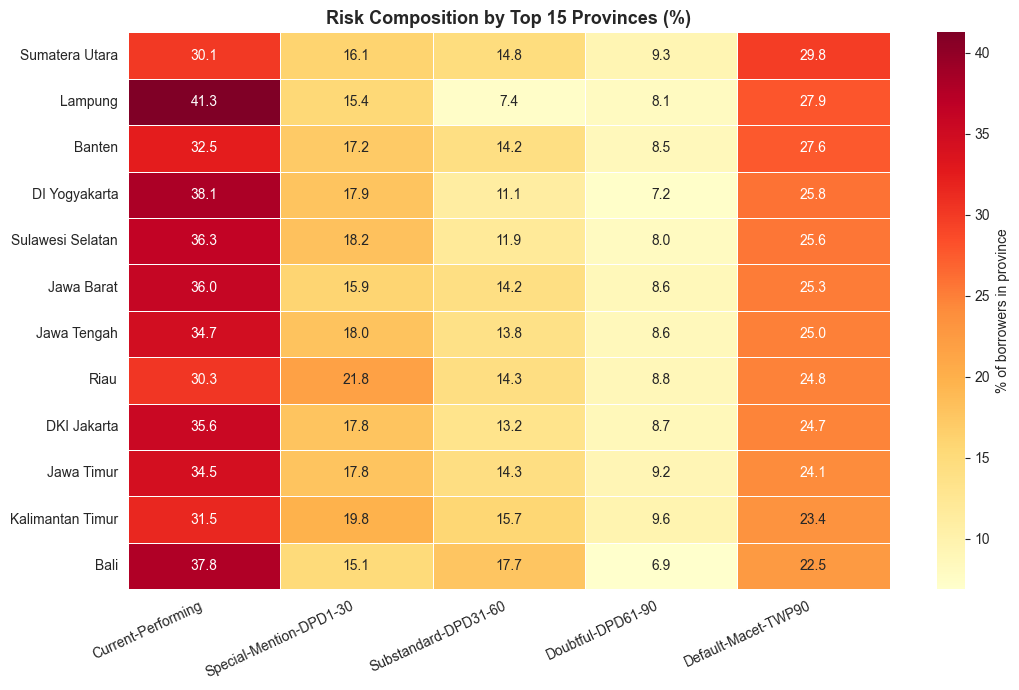

In [11]:
top = df['province'].value_counts().nlargest(15).index
pivot = pd.crosstab(df.loc[df['province'].isin(top), 'province'],
                    df.loc[df['province'].isin(top), 'twp90_default_status'],
                    normalize='index') * 100
pivot = pivot[RISK_ORDER]
pivot = pivot.loc[pivot['Default-Macet-TWP90'].sort_values(ascending=False).index]

plt.figure(figsize=(11,7))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.4,
            cbar_kws={'label':'% of borrowers in province'})
plt.title('Risk Composition by Top 15 Provinces (%)')
plt.ylabel(''); plt.xlabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout(); plt.show()

Text(0.5, 1.0, 'Number of Borrowers by Province')

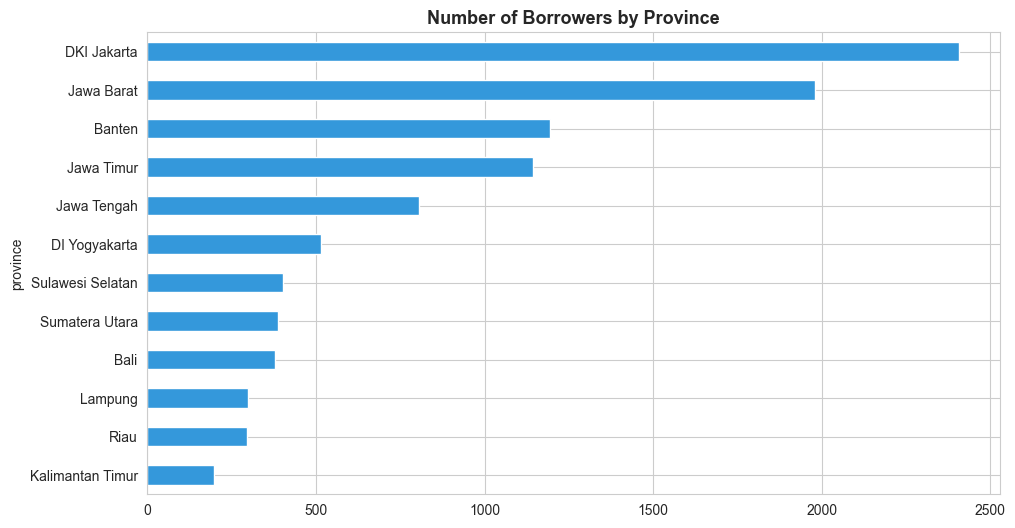

In [12]:
plt.figure(figsize=(11,5))
df['province'].value_counts().sort_values().head(15).plot(kind='barh', figsize=(11,6), color='#3498DB', edgecolor='white')
plt.title('Number of Borrowers by Province')

## Scatter + Trend by Risk Level (Income vs Installment)
### Shows whether installment/income ratio worsens progressively across risk tiers — 5 regression lines makes the gradient visible.

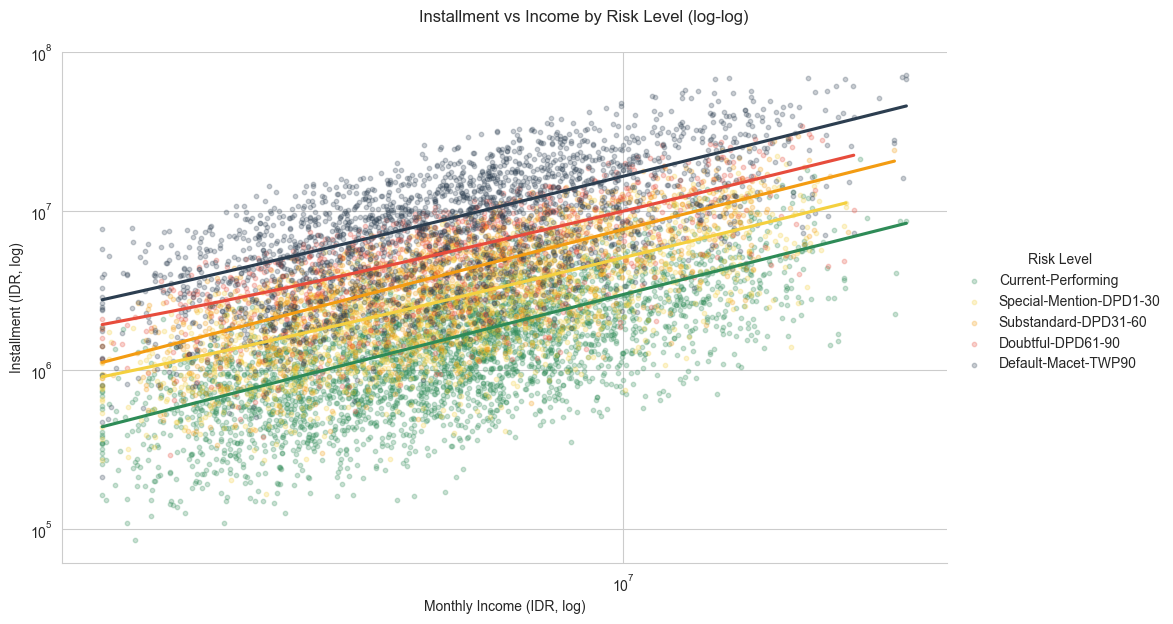

In [13]:
g = sns.lmplot(data=df, x='monthly_income_idr', y='monthly_installment_estimate_idr',
               hue='twp90_default_status', hue_order=RISK_ORDER,
               palette=RISK_PALETTE, scatter_kws={'alpha':0.25,'s':10},
               height=6, aspect=1.6, ci=None)
g.set(xscale='log', yscale='log')
g.set_axis_labels('Monthly Income (IDR, log)', 'Installment (IDR, log)')
g.fig.suptitle('Installment vs Income by Risk Level (log-log)', y=1.02)
g._legend.set_title('Risk Level')
plt.show()

## Distress Index — Binned Distribution Stacked by Risk
### Validates whether financial_distress_index progressively separates higher-risk bands — a much stronger validation than binary.

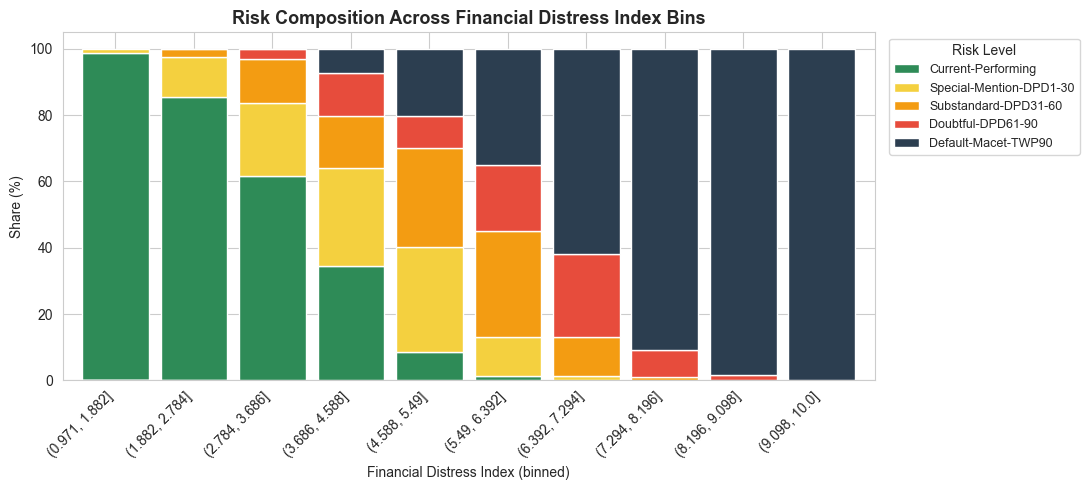

In [14]:
df['distress_bin'] = pd.cut(df['financial_distress_index'], bins=10)
cross = pd.crosstab(df['distress_bin'], df['twp90_default_status'], normalize='index') * 100
cross = cross[RISK_ORDER]

ax = cross.plot(kind='bar', stacked=True, figsize=(11,5), width=0.85, color=RISK_PALETTE, edgecolor='white')
ax.set_title('Risk Composition Across Financial Distress Index Bins')
ax.set_xlabel('Financial Distress Index (binned)'); ax.set_ylabel('Share (%)')
ax.legend(title='Risk Level', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

## Correlation — Ordinal Risk Score vs Numeric Features
### Using the ordinal encoding (risk_score), you can now see Spearman correlations — the correct choice for an ordered target. Sorted horizontal bar makes ranking trivial.

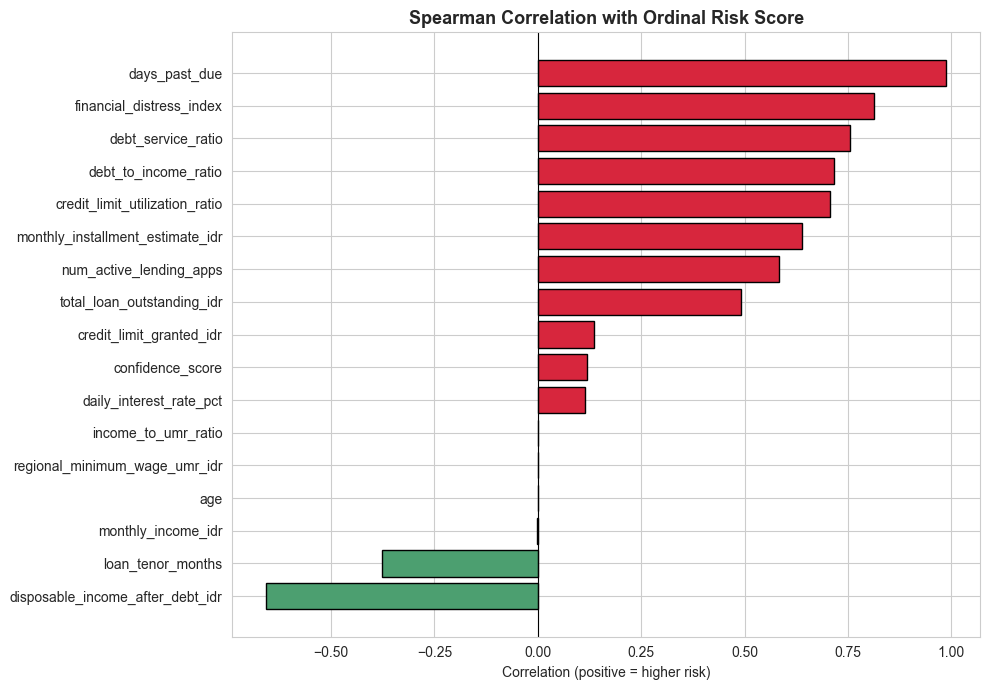

In [15]:
num_cols = df.select_dtypes('number').columns.drop(['risk_score','is_high_risk'], errors='ignore')
corrs = df[num_cols].corrwith(df['risk_score'], method='spearman').sort_values()

plt.figure(figsize=(10,7))
colors = ['#D7263D' if v>0 else '#4C9F70' for v in corrs]
plt.barh(corrs.index, corrs.values, color=colors, edgecolor='black')
plt.axvline(0, color='black', lw=0.8)
plt.title('Spearman Correlation with Ordinal Risk Score')
plt.xlabel('Correlation (positive = higher risk)'); plt.ylabel('')
plt.tight_layout(); plt.show()

## Loan Purpose — Multi-KPI with Risk Gradient
### Now shows share of each risk class within each purpose + an aggregate risk score column — richer than a single default rate.

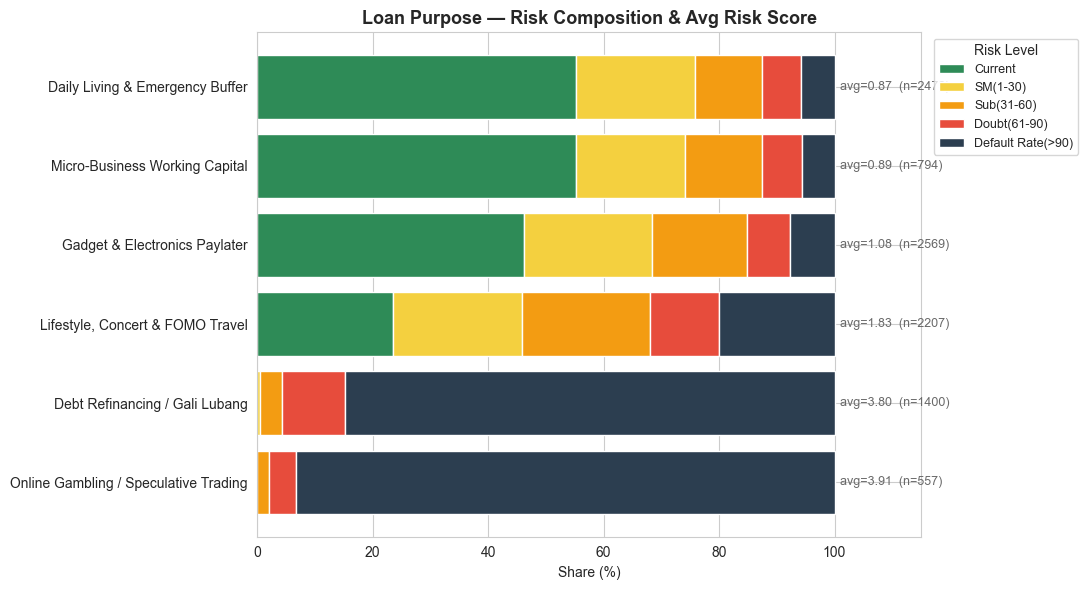

In [16]:
g = df.groupby('primary_loan_purpose').agg(
    n=('risk_score','size'),
    avg_risk=('risk_score','mean'),
    high_risk_pct=('is_high_risk','mean'),
).query('n >= 50').sort_values('avg_risk', ascending=False)

comp = pd.crosstab(df['primary_loan_purpose'], df['twp90_default_status'], normalize='index') * 100
comp = comp.loc[g.index, RISK_ORDER]

fig, ax = plt.subplots(figsize=(11,6))
left = np.zeros(len(comp))
for i, col in enumerate(RISK_ORDER):
    ax.barh(comp.index, comp[col], left=left, color=RISK_PALETTE[i], label=SHORT[col], edgecolor='white')
    left += comp[col].values
for i, purpose in enumerate(comp.index):
    ax.text(101, i, f'avg={g.loc[purpose,"avg_risk"]:.2f}  (n={g.loc[purpose,"n"]})',
            va='center', fontsize=9, color='dimgray')
ax.set_xlim(0, 115)
ax.set_title('Loan Purpose — Risk Composition & Avg Risk Score')
ax.set_xlabel('Share (%)'); ax.set_ylabel('')
ax.legend(title='Risk Level', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## Risk Matrix Bubble — Employment Segment (Volume × High-Risk Rate × Exposure)
### 3-D business view, but now "high risk %" = DPD>60 rate (a stricter, more actionable KPI than binary default). Still the boardroom chart.

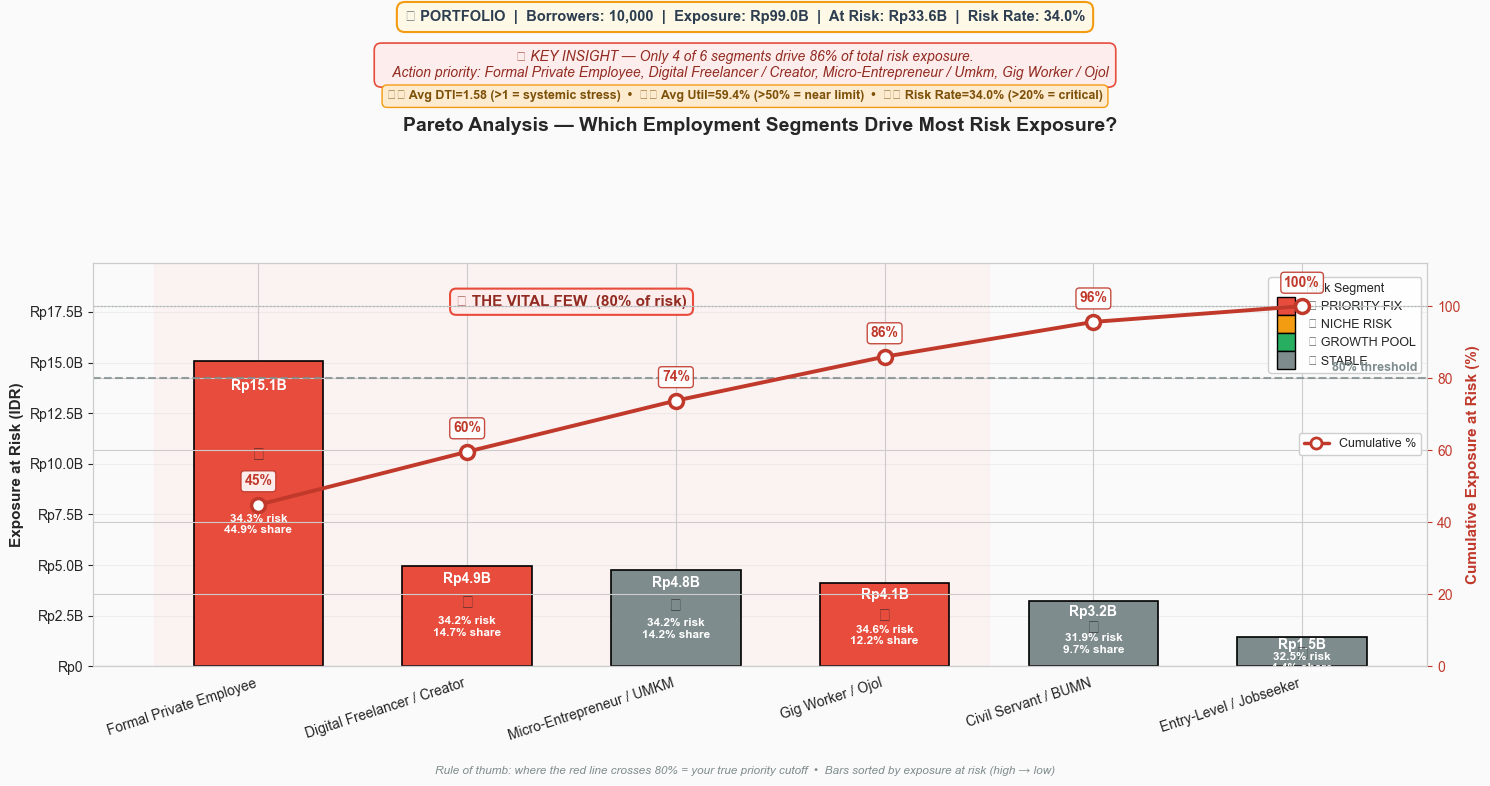


📊 PARETO ANALYSIS — BUSINESS INTERPRETATION

💼 PORTFOLIO SUMMARY
   • Total Borrowers         : 10,000
   • Total Exposure          : Rp99.0B
   • Total Exposure at Risk  : Rp33.6B
   • Portfolio High-Risk Rate: 34.0%

🎯 THE 80/20 INSIGHT
   Only 4 out of 6 segments drive 86% of total exposure at risk.
   → These are your TRUE priority for credit policy tightening.

────────────────────────────────────────────────────────────────────────────────────────────────────
📋 SEGMENT-BY-SEGMENT BREAKDOWN (sorted by exposure at risk)
────────────────────────────────────────────────────────────────────────────────────────────────────

🔴 #1  FORMAL PRIVATE EMPLOYEE   [PRIORITY FIX]
      Share of total risk   :  44.9%   |   Cumulative:  44.9%
      Borrowers             : 3,856
      High-Risk Rate (DPD>60): 34.3%
      Total Exposure        : Rp44.0B
      Exposure at Risk      : Rp15.1B
      Avg Loan / DTI / Util : Rp11.4M / 1.59 / 59.0%

🔴 #2  DIGITAL FREELANCER / CREATOR   [PRIORITY FIX]
   

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

# ---------- Formatter ----------
def idr_fmt(value, pos=None):
    if value >= 1_000_000_000: return f"Rp{value/1e9:.1f}B"
    if value >= 1_000_000:     return f"Rp{value/1e6:.1f}M"
    if value >= 1_000:         return f"Rp{value/1e3:.0f}K"
    return f"Rp{value:,.0f}"

# ---------- Build segment table ----------
seg = df.groupby("employment_status").agg(
    n=("is_high_risk", "size"),
    high_risk_rate=("is_high_risk", "mean"),
    exposure=("total_loan_outstanding_idr", "sum"),
    avg_loan=("total_loan_outstanding_idr", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    avg_util=("credit_limit_utilization_ratio", "mean"),
).reset_index()
seg["exposure_at_risk"] = seg["exposure"] * seg["high_risk_rate"]

# ---------- Quadrant classification ----------
n_thresh    = seg["n"].median()
risk_thresh = seg["high_risk_rate"].median()

def classify(r):
    if r["n"] >= n_thresh and r["high_risk_rate"] >= risk_thresh: return "PRIORITY FIX"
    if r["n"] <  n_thresh and r["high_risk_rate"] >= risk_thresh: return "NICHE RISK"
    if r["n"] >= n_thresh and r["high_risk_rate"] <  risk_thresh: return "GROWTH POOL"
    return "STABLE"
seg["segment"] = seg.apply(classify, axis=1)

SEG_COLOR = {"PRIORITY FIX":"#E74C3C", "NICHE RISK":"#F39C12",
             "GROWTH POOL":"#27AE60", "STABLE":"#7F8C8D"}
SEG_LABEL = {"PRIORITY FIX":"🔴 PRIORITY FIX", "NICHE RISK":"🟡 NICHE RISK",
             "GROWTH POOL":"🟢 GROWTH POOL", "STABLE":"⚫ STABLE"}

# ---------- Pareto ----------
s = seg.sort_values("exposure_at_risk", ascending=False).reset_index(drop=True)
s["cum_pct"] = s["exposure_at_risk"].cumsum() / s["exposure_at_risk"].sum() * 100

total_at_risk  = s["exposure_at_risk"].sum()
total_exposure = s["exposure"].sum()
portfolio_rate = total_at_risk / total_exposure

cutoff_idx = next((i for i, c in enumerate(s["cum_pct"]) if c >= 80), len(s)-1)
critical = s.iloc[:cutoff_idx+1]
rest     = s.iloc[cutoff_idx+1:]

# ---------- Portfolio-level averages (for red flags) ----------
avg_dti_all  = seg["avg_dti"].mean()
avg_util_all = seg["avg_util"].mean()

# ============================================================
# CHART
# ============================================================
fig, ax1 = plt.subplots(figsize=(15, 8))
fig.patch.set_facecolor("#FAFAFA")
ax1.set_facecolor("#FAFAFA")

x = np.arange(len(s))

# ---------- Highlight zone: "Vital Few" ----------
ax1.axvspan(-0.5, cutoff_idx+0.5, color="#FDEDEC", alpha=0.55, zorder=0)
ax1.text((cutoff_idx)/2, s["exposure_at_risk"].max()*1.18,
         "🎯 THE VITAL FEW  (80% of risk)", ha="center",
         fontsize=11, fontweight="bold", color="#922B21",
         bbox=dict(boxstyle="round,pad=0.4", fc="#FDEDEC", ec="#E74C3C", lw=1.5))

# ---------- Bars ----------
bars = ax1.bar(x, s["exposure_at_risk"],
               color=[SEG_COLOR[t] for t in s["segment"]],
               edgecolor="black", width=0.62, zorder=2, linewidth=1.2)

# ---------- Bar value labels (inside top of bar) ----------
for b, v, seg_t in zip(bars, s["exposure_at_risk"], s["segment"]):
    ax1.text(b.get_x()+b.get_width()/2, v*0.94, idr_fmt(v),
             ha="center", va="top", fontsize=10, fontweight="bold",
             color="white", zorder=4)
    # Segment badge inside bar
    ax1.text(b.get_x()+b.get_width()/2, v*0.72, SEG_LABEL[seg_t].split()[0],
             ha="center", va="top", fontsize=13, zorder=4)
    # ⚡ NEW: risk % + share of total risk inside bar
    row = s.loc[s["exposure_at_risk"] == v].iloc[0]
    share_of_total = row["exposure_at_risk"] / total_at_risk * 100
    ax1.text(b.get_x()+b.get_width()/2, v*0.50,
             f"{row['high_risk_rate']:.1%} risk\n{share_of_total:.1f}% share",
             ha="center", va="top", fontsize=8.5, color="white",
             fontweight="bold", zorder=4)

ax1.set_ylabel("Exposure at Risk (IDR)", fontweight="bold", fontsize=11)
ax1.yaxis.set_major_formatter(FuncFormatter(idr_fmt))
ax1.set_ylim(0, s["exposure_at_risk"].max() * 1.32)
ax1.set_xticks(x)
ax1.set_xticklabels(s["employment_status"], rotation=18, ha="right", fontsize=10)
ax1.grid(axis="y", alpha=0.25, zorder=0)
ax1.set_axisbelow(True)

# ---------- Secondary axis: cumulative % ----------
ax2 = ax1.twinx()
ax2.plot(x, s["cum_pct"], color="#C0392B", marker="o", lw=2.8,
         markersize=10, markerfacecolor="white", markeredgewidth=2.5,
         label="Cumulative %", zorder=5)
ax2.set_ylabel("Cumulative Exposure at Risk (%)", fontweight="bold",
               fontsize=11, color="#C0392B")
ax2.set_ylim(0, 112)
ax2.tick_params(axis='y', colors="#C0392B")

# ---------- 80% threshold ----------
ax2.axhline(80, color="#7F8C8D", ls="--", lw=1.5, alpha=0.8, zorder=1)
ax2.text(len(s)-0.45, 82, "80% threshold", fontsize=9, color="#7F8C8D",
         fontweight="bold", ha="right")

# ---------- 100% reference ----------
ax2.axhline(100, color="#95A5A6", ls=":", lw=1, alpha=0.6, zorder=1)

# ---------- Cumulative % annotations ----------
for i, c in enumerate(s["cum_pct"]):
    ax2.annotate(f"{c:.0f}%", xy=(i, c), xytext=(0, 14),
                 textcoords="offset points", ha="center", fontsize=10,
                 color="#C0392B", fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.25", fc="white",
                           ec="#C0392B", lw=1, alpha=0.9),
                 zorder=6)

# ============================================================
# HEADER LAYERS (Title + KPI + Insight)
# ============================================================

# ---------- Layer 1: KPI summary banner ----------
kpi_text = (
    f"💼 PORTFOLIO  |  Borrowers: {s['n'].sum():,}  |  "
    f"Exposure: {idr_fmt(total_exposure)}  |  "
    f"At Risk: {idr_fmt(total_at_risk)}  |  "
    f"Risk Rate: {portfolio_rate:.1%}"
)
fig.text(0.5, 0.965, kpi_text, ha="center", va="top", fontsize=10.5,
         color="#2C3E50", fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.55", fc="#FEF9E7",
                   ec="#F39C12", lw=1.5))

# ---------- Layer 2: 80/20 Insight ----------
insight = (
    f"⚡ KEY INSIGHT — Only {cutoff_idx+1} of {len(s)} segments drive "
    f"{s['cum_pct'].iloc[cutoff_idx]:.0f}% of total risk exposure.\n"
    f"   Action priority: {', '.join(s.iloc[:cutoff_idx+1]['employment_status'].str.title())}"
)
fig.text(0.5, 0.915, insight, ha="center", va="top", fontsize=10,
         color="#922B21", style="italic",
         bbox=dict(boxstyle="round,pad=0.5", fc="#FDEDEC",
                   ec="#E74C3C", lw=1.2))

# ---------- Layer 3: Portfolio red flags banner ----------
red_flags = []
if avg_dti_all > 1.0:
    red_flags.append(f"⚠️ Avg DTI={avg_dti_all:.2f} (>1 = systemic stress)")
if avg_util_all > 0.5:
    red_flags.append(f"⚠️ Avg Util={avg_util_all:.1%} (>50% = near limit)")
if portfolio_rate > 0.2:
    red_flags.append(f"⚠️ Risk Rate={portfolio_rate:.1%} (>20% = critical)")

if red_flags:
    fig.text(0.5, 0.865, "  •  ".join(red_flags),
             ha="center", va="top", fontsize=9,
             color="#7E5109", fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.4", fc="#FDEBD0",
                       ec="#F39C12", lw=1))

# ---------- Main axis title ----------
ax1.set_title("Pareto Analysis — Which Employment Segments Drive Most Risk Exposure?",
              fontsize=14, fontweight="bold", pad=95)

# ============================================================
# LEGENDS
# ============================================================
seg_legend = [Line2D([0],[0], marker="s", color="w", label=SEG_LABEL[k],
                     markerfacecolor=SEG_COLOR[k], markersize=13,
                     markeredgecolor="black")
              for k in SEG_COLOR]
ax1.legend(handles=seg_legend, title="Risk Segment", loc="upper right",
           fontsize=9, title_fontsize=9, framealpha=0.95,
           bbox_to_anchor=(1.0, 0.98))

line_legend = [Line2D([0],[0], color="#C0392B", marker="o", lw=2.5,
                      markersize=8, markerfacecolor="white",
                      markeredgewidth=2, label="Cumulative %")]
ax2.legend(handles=line_legend, loc="center right",
           fontsize=9, framealpha=0.95, bbox_to_anchor=(1.0, 0.55))

# ---------- Footer ----------
fig.text(0.5, 0.01,
         "Rule of thumb: where the red line crosses 80% = your true priority cutoff  •  "
         "Bars sorted by exposure at risk (high → low)",
         ha="center", fontsize=8.5, color="#7F8C8D", style="italic")

plt.tight_layout(rect=[0, 0.03, 1, 0.85])
plt.show()

# ============================================================
# OPTIONAL: PRINT FULL DETAILED REPORT
# ============================================================
print("\n" + "="*100)
print("📊 PARETO ANALYSIS — BUSINESS INTERPRETATION")
print("="*100)

print(f"\n💼 PORTFOLIO SUMMARY")
print(f"   • Total Borrowers         : {s['n'].sum():,}")
print(f"   • Total Exposure          : {idr_fmt(total_exposure)}")
print(f"   • Total Exposure at Risk  : {idr_fmt(total_at_risk)}")
print(f"   • Portfolio High-Risk Rate: {portfolio_rate:.1%}")

print(f"\n🎯 THE 80/20 INSIGHT")
print(f"   Only {len(critical)} out of {len(s)} segments drive "
      f"{critical['cum_pct'].iloc[-1]:.0f}% of total exposure at risk.")
print(f"   → These are your TRUE priority for credit policy tightening.\n")

print("─"*100)
print("📋 SEGMENT-BY-SEGMENT BREAKDOWN (sorted by exposure at risk)")
print("─"*100)

for i, r in s.iterrows():
    marker = "🔴" if i <= cutoff_idx else "⚪"
    share  = r["exposure_at_risk"] / total_at_risk * 100
    print(f"\n{marker} #{i+1}  {r['employment_status'].upper()}   [{r['segment']}]")
    print(f"      Share of total risk   : {share:5.1f}%   |   Cumulative: {r['cum_pct']:5.1f}%")
    print(f"      Borrowers             : {r['n']:,}")
    print(f"      High-Risk Rate (DPD>60): {r['high_risk_rate']:.1%}")
    print(f"      Total Exposure        : {idr_fmt(r['exposure'])}")
    print(f"      Exposure at Risk      : {idr_fmt(r['exposure_at_risk'])}")
    print(f"      Avg Loan / DTI / Util : {idr_fmt(r['avg_loan'])} / {r['avg_dti']:.2f} / {r['avg_util']:.1%}")

print("\n" + "="*100)
print("🎯 PRIORITY-BASED ACTION PLAN")
print("="*100)

print("\n🔴 IMMEDIATE ACTION (top segments driving 80% of risk):")
for _, r in critical.iterrows():
    print(f"   • {r['employment_status']}  ({idr_fmt(r['exposure_at_risk'])} at risk)")
    print(f"     → Tighten approval · raise pricing · early-collection SMS/WA/push")
    print(f"     → Review underwriting rules for DTI={r['avg_dti']:.2f}, "
          f"Util={r['avg_util']:.1%}")

if len(rest) > 0:
    print("\n⚪ MONITOR / MAINTAIN (remaining segments):")
    for _, r in rest.iterrows():
        print(f"   • {r['employment_status']}  ({idr_fmt(r['exposure_at_risk'])} at risk)")
        if r["segment"] == "STABLE":
            print(f"     → Maintain. Re-check quarterly.")
        elif r["segment"] == "GROWTH POOL":
            print(f"     → Safe to up-sell. Raise limits selectively.")
        elif r["segment"] == "NICHE RISK":
            print(f"     → Manual review. Consider phasing out.")

print("\n" + "="*100)
print("⚠️  PORTFOLIO-WIDE RED FLAGS")
print("="*100)
print(f"\n   1) Avg DTI across segments = {avg_dti_all:.2f} "
      f"{'🚨 (>1.0 means debt > income — systemic risk)' if avg_dti_all > 1 else '✅'}")
print(f"   2) Avg Utilization = {avg_util_all:.1%} "
      f"{'🚨 (>50% = customers are near limit)' if avg_util_all > 0.5 else '✅'}")
print(f"   3) Portfolio high-risk rate = {portfolio_rate:.1%} "
      f"{'🚨 (>20% = industry-critical)' if portfolio_rate > 0.2 else '✅'}")
print(f"   4) Risk concentration — top {len(critical)} segments control "
      f"{critical['cum_pct'].iloc[-1]:.0f}% of total risk (Pareto effect).")
print("\n" + "="*100 + "\n")